In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url="https://raw.githubusercontent.com/mohammadjubaid76-collab/adult_income_ml/main/adult.csv"
df=pd.read_csv(url, na_values="?")
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [3]:
print("First 10 records:",df.head(10))
print("Last 10 records:",df.tail(10))
print("Dataset information:",df.info())
print("Descriptive statistics:",df.describe(include="all"))

First 10 records:    age    workclass  fnlwgt     education  education.num marital.status  \
0   90          NaN   77053       HS-grad              9        Widowed   
1   82      Private  132870       HS-grad              9        Widowed   
2   66          NaN  186061  Some-college             10        Widowed   
3   54      Private  140359       7th-8th              4       Divorced   
4   41      Private  264663  Some-college             10      Separated   
5   34      Private  216864       HS-grad              9       Divorced   
6   38      Private  150601          10th              6      Separated   
7   74    State-gov   88638     Doctorate             16  Never-married   
8   68  Federal-gov  422013       HS-grad              9       Divorced   
9   41      Private   70037  Some-college             10  Never-married   

          occupation    relationship   race     sex  capital.gain  \
0                NaN   Not-in-family  White  Female             0   
1    Exec-manageri

In [4]:
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

2. Data Preprocessing

In [5]:
categorical_missing = ['workclass', 'occupation', 'native.country']

for col in categorical_missing:
    df[col] = df[col].fillna(df[col].mode()[0])

In [6]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

In [7]:
categorical_cols = df.select_dtypes(include='object').columns

print(categorical_cols)

Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income'],
      dtype='str')


C:\Users\DELL\AppData\Local\Temp\ipykernel_8232\1616883611.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns


In [8]:

X = df.drop('income', axis=1)
y = df['income']

categorical_cols = X.select_dtypes(include='object').columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", X.shape)
X.head()

Shape after encoding: (32561, 97)


C:\Users\DELL\AppData\Local\Temp\ipykernel_8232\710248711.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,...,native.country_Portugal,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia
0,90,77053,9,0,4356,40,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
1,82,132870,9,0,4356,18,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
2,66,186061,10,0,4356,40,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
3,54,140359,4,0,3900,40,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,41,264663,10,0,3900,40,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

print("Scaled numerical features:")
print(X[numeric_cols].head())

Scaled numerical features:
        age    fnlwgt  education.num  capital.gain  capital.loss  \
0  3.769612 -1.067997      -0.420060      -0.14592     10.593507   
1  3.183112 -0.539169      -0.420060      -0.14592     10.593507   
2  2.010110 -0.035220      -0.031360      -0.14592     10.593507   
3  1.130359 -0.468215      -2.363558      -0.14592      9.461864   
4  0.177296  0.709482      -0.031360      -0.14592      9.461864   

   hours.per.week  workclass_Local-gov  workclass_Never-worked  \
0       -0.035429            -0.262097               -0.014664   
1       -1.817204            -0.262097               -0.014664   
2       -0.035429            -0.262097               -0.014664   
3       -0.035429            -0.262097               -0.014664   
4       -0.035429            -0.262097               -0.014664   

   workclass_Private  workclass_Self-emp-inc  ...  native.country_Portugal  \
0            0.57209               -0.188389  ...                -0.033729   
1          

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (22792, 97)
Validation set: (4884, 97)
Testing set: (4885, 97)


In [11]:
preprocessed_df = X.copy()
preprocessed_df['income'] = y.values

preprocessed_df.to_csv("adult_income_preprocessed.csv", index=False)

print("CSV file created successfully!")

CSV file created successfully!


### 4. Feature Selection using Correlation Matrix

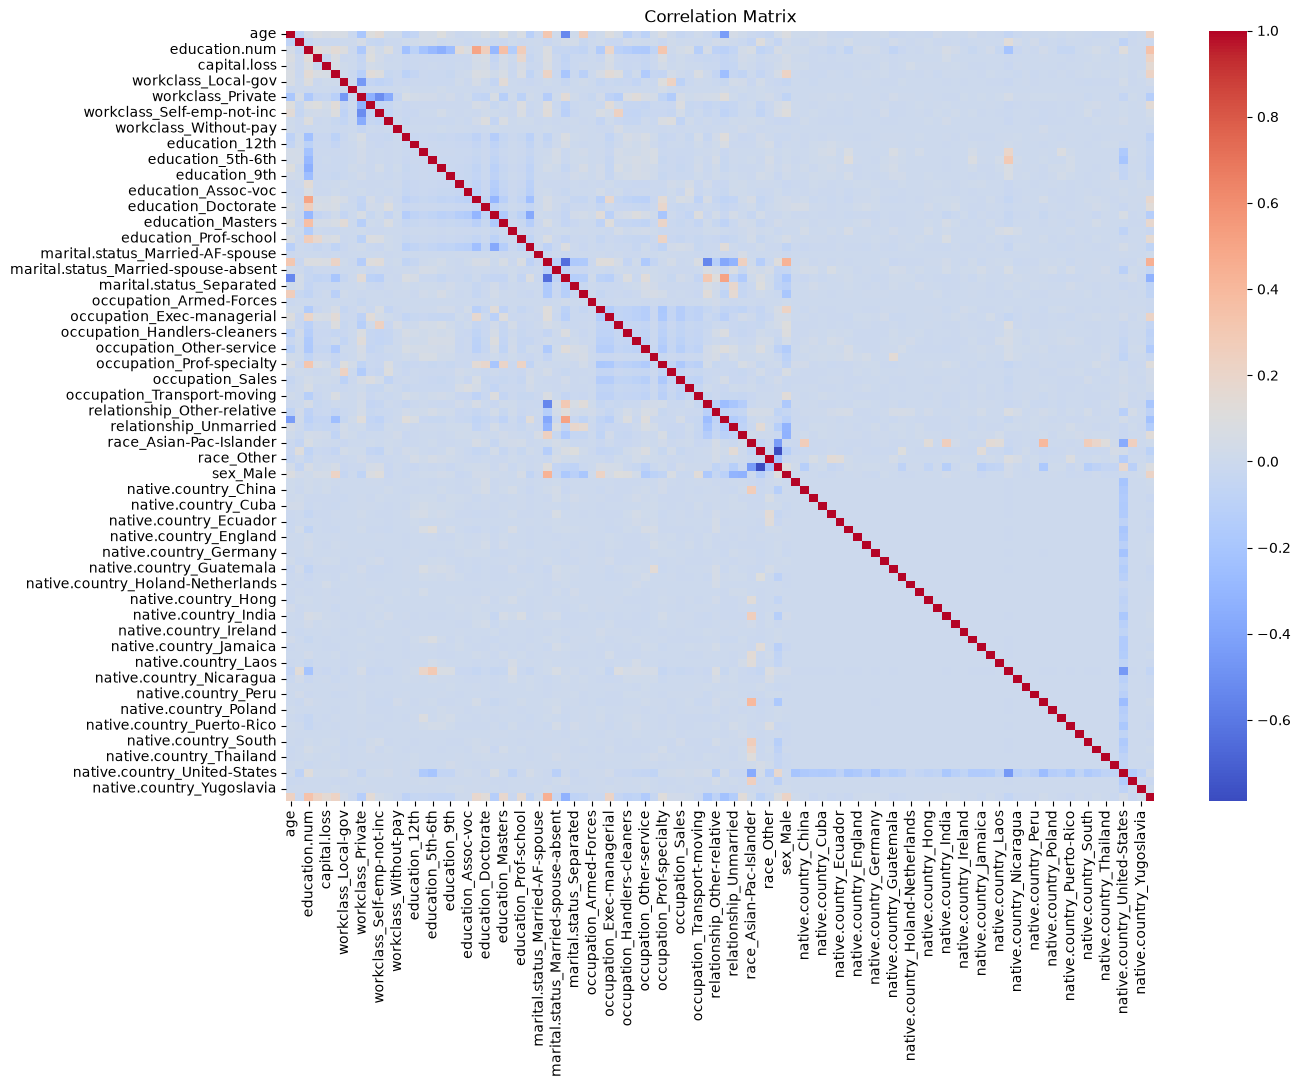

Top 5 features by absolute correlation with income:
marital.status_Married-civ-spouse    0.448304
education.num                        0.337458
marital.status_Never-married         0.320187
age                                  0.234856
relationship_Own-child               0.228089
Name: income, dtype: float64


In [12]:

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)


corr_df = X_train.copy()
corr_df['income'] = y_train_encoded


corr_matrix = corr_df.corr()


plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


target_corr = (
    corr_matrix['income']
    .drop('income')
    .abs()
    .sort_values(ascending=False)
)

print("Top 5 features by absolute correlation with income:")
print(target_corr.head(5))

### 4.1 Feature Selection using SelectKBest

In [13]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select the top 5 features
selector = SelectKBest(score_func=f_classif, k=5)

X_train_selected = selector.fit_transform(
    X_train,
    y_train_encoded
)

selected_features = X_train.columns[selector.get_support()]

print("Top 5 features using SelectKBest:")
print(list(selected_features))

# Display feature scores
feature_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'Score': selector.scores_
}).sort_values(by='Score', ascending=False)

print("\nFeature scores:")
print(feature_scores.head(10))

Top 5 features using SelectKBest:
['age', 'education.num', 'marital.status_Married-civ-spouse', 'marital.status_Never-married', 'relationship_Own-child']

Feature scores:
                              Feature        Score
29  marital.status_Married-civ-spouse  5732.305619
2                       education.num  2928.798065
31       marital.status_Never-married  2603.313814
0                                 age  1330.424093
49             relationship_Own-child  1250.702331
3                        capital.gain  1204.904916
5                      hours.per.week  1202.430581
36         occupation_Exec-managerial  1136.018459
56                           sex_Male  1071.730002
47         relationship_Not-in-family   890.344090


In [14]:

top_corr_features = list(target_corr.head(5).index)
selectkbest_features = list(selected_features)

common_features = set(top_corr_features).intersection(selectkbest_features)

print("Top 5 Correlation features:")
print(top_corr_features)

print("\nTop 5 SelectKBest features:")
print(selectkbest_features)

print("\nCommon important features:")
print(list(common_features))

Top 5 Correlation features:
['marital.status_Married-civ-spouse', 'education.num', 'marital.status_Never-married', 'age', 'relationship_Own-child']

Top 5 SelectKBest features:
['age', 'education.num', 'marital.status_Married-civ-spouse', 'marital.status_Never-married', 'relationship_Own-child']

Common important features:
['marital.status_Never-married', 'age', 'marital.status_Married-civ-spouse', 'education.num', 'relationship_Own-child']


## 5. Compare Dataset Before and After Preprocessing

In [15]:


df_original = pd.read_csv("adult.csv")
df_original = df_original.replace('?', pd.NA)

print("Original dataset shape:", df_original.shape)
print("Processed dataset shape:", df.shape)


Original dataset shape: (32561, 15)
Processed dataset shape: (32561, 15)


Missing values before preprocessing: 4262
Missing values after preprocessing: 0


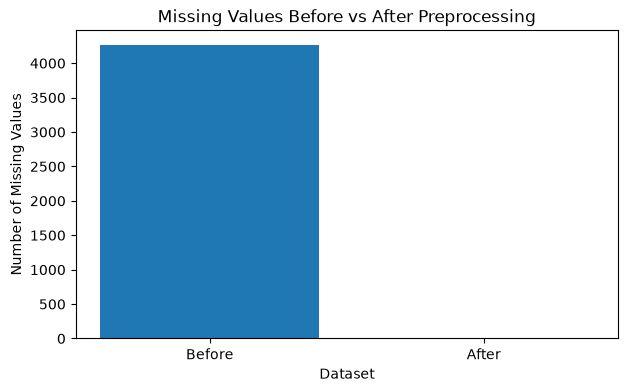

In [16]:

before_missing = df_original.isna().sum().sum()
after_missing = df.isna().sum().sum()

print("Missing values before preprocessing:", before_missing)
print("Missing values after preprocessing:", after_missing)

plt.figure(figsize=(7, 4))
plt.bar(
    ["Before", "After"],
    [before_missing, after_missing]
)
plt.title("Missing Values Before vs After Preprocessing")
plt.xlabel("Dataset")
plt.ylabel("Number of Missing Values")
plt.show()


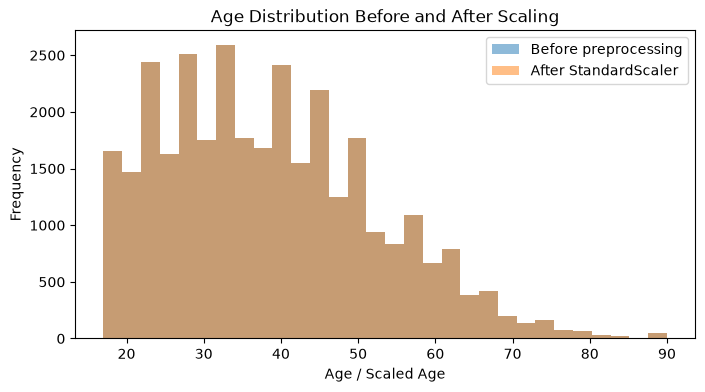

In [21]:
plt.figure(figsize=(8,4))

plt.hist(
    df_original['age'].dropna(),
    bins=30,
    alpha=0.5,
    label='Before preprocessing'
)

plt.hist(
    df['age'],
    bins=30,
    alpha=0.5,
    label='After StandardScaler'
)

plt.title('Age Distribution Before and After Scaling')
plt.xlabel('Age / Scaled Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

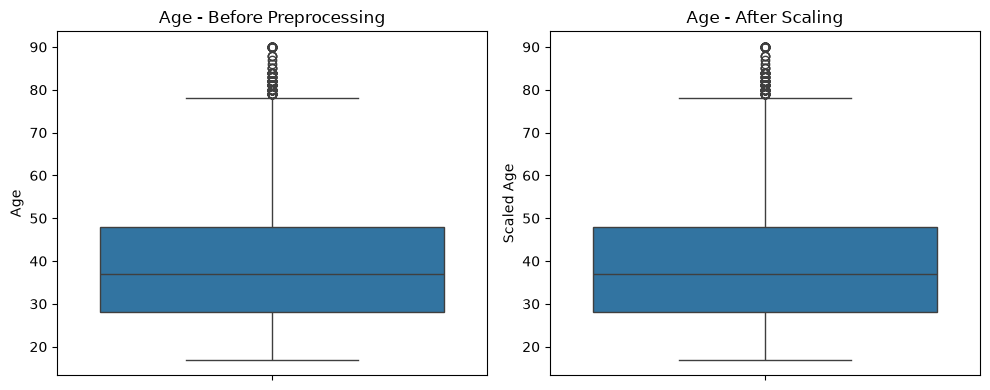

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=df_original['age'].dropna(), ax=axes[0])
axes[0].set_title('Age - Before Preprocessing')
axes[0].set_ylabel('Age')

sns.boxplot(y=df['age'], ax=axes[1])
axes[1].set_title('Age - After Scaling')
axes[1].set_ylabel('Scaled Age')

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_296\4199439995.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_before = df_original.select_dtypes(include='object').columns


Categorical columns before encoding:
['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']

Encoded columns after encoding:
['workclass_Local-gov', 'workclass_Never-worked', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'workclass_Without-pay', 'education_11th', 'education_12th', 'education_1st-4th', 'education_5th-6th', 'education_7th-8th', 'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors', 'education_Doctorate', 'education_HS-grad', 'education_Masters', 'education_Preschool', 'education_Prof-school', 'education_Some-college', 'marital.status_Married-AF-spouse', 'marital.status_Married-civ-spouse', 'marital.status_Married-spouse-absent', 'marital.status_Never-married', 'marital.status_Separated', 'marital.status_Widowed', 'occupation_Armed-Forces', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing',

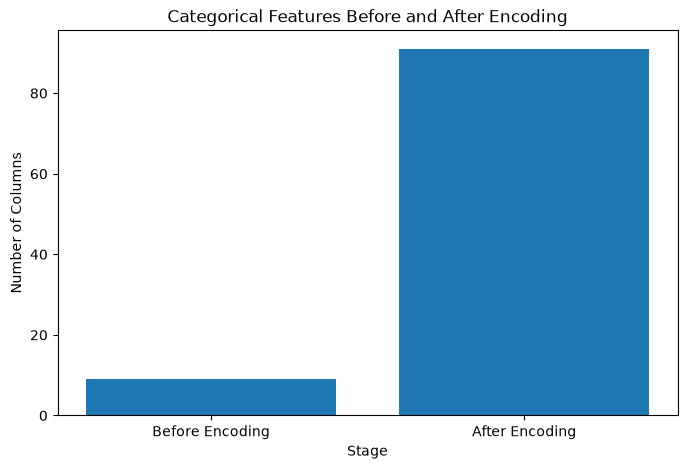

In [19]:

categorical_cols_before = df_original.select_dtypes(include='object').columns
before_count = len(categorical_cols_before)


encoded_cols = [
    col for col in X.columns
    if any(col.startswith(cat + "_") for cat in categorical_cols_before)
]

after_count = len(encoded_cols)

print("Categorical columns before encoding:")
print(list(categorical_cols_before))

print("\nEncoded columns after encoding:")
print(encoded_cols)

print("\nBefore encoding:", before_count)
print("After encoding:", after_count)


plt.figure(figsize=(8, 5))

plt.bar(
    ["Before Encoding", "After Encoding"],
    [before_count, after_count]
)

plt.title("Categorical Features Before and After Encoding")
plt.xlabel("Stage")
plt.ylabel("Number of Columns")

plt.show()

Conculsion
In this project, I worked on preprocessing the Adult Income dataset and prepared it for further machine learning analysis. First, I loaded the dataset and examined its structure, basic statistics, and missing values. The missing values were handled appropriately, and categorical features were converted into numerical form using one-hot encoding. Numerical features were standardized using StandardScaler so that features with different ranges could be compared properly. The dataset was then divided into training, validation, and testing sets to support reliable analysis. For feature selection, I used both a correlation matrix and SelectKBest to identify important features related to the income prediction task. I also compared the dataset before and after preprocessing using suitable visualizations to understand the changes in data quality. Overall, this project helped me understand how raw data can be cleaned, transformed, and prepared for machine learning. The final preprocessed dataset provides a suitable foundation for further model development and income classification.